# **Identity Document Fraud Detection**
### Binary Classification: Data Preparation, Modeling, and Evaluation

**AI Studio Challenge**  
**Industry Partner:** Verizon  
**Milestone:** September — Binary Classification  
**Dataset:** IDNet Identity Document Analysis Dataset (Kaggle subset)

---



## **1. Project Overview**
The goal of our project is to develop a binary classification model that distinguishes between genuine and fake identity documents in the context of Verizon's customer onboarding process.

In this notebook, we:
1. Explore the IDNet dataset and sample 600 images: 200 each of driver's licenses (West Virginia), national IDs (Russia), and passports (Greece)
2. Generate synthetic fake documents for half of each category using Gaussian blur (whole-image and partial) combined with added noise
3. Extract HOG and LBP features from each image
4. Split the data 80/20 into training and test sets
5. Train and compare seven classifiers: Logistic Regression, SVM, Random Forest, Decision Tree, Extra Trees, AdaBoost, and Gradient Boosting
6. Evaluate the models with accuracy, precision, recall, F1, ROC-AUC, confusion matrices, and cross-validation
7. Demo: classify an uploaded document image

## **2. Setup**
Import the libraries needed for dataset exploration, image processing, and visualization.

In [2]:
import os
import glob
import shutil
import zipfile
from collections import Counter

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

## **3. Dataset Exploration**

### 3.1 Upload & extract raw_sample.zip


In [4]:
from google.colab import files
uploaded = files.upload()

Saving raw_sample.zip to raw_sample.zip


In [5]:
with zipfile.ZipFile("raw_sample.zip", 'r') as z:
    z.extractall("/content/raw_sample")

print(f"Total files: {len(os.listdir('/content/raw_sample'))}")

Total files: 600


### 3.2 Dataset Structure (counts per category)


In [6]:
raw_dir = "/content/raw_sample"
all_files = os.listdir(raw_dir)

labels = ["drivers_license", "national_id", "passport"]
counts = Counter()
for f in all_files:
    for label in labels:
        if f.startswith(label):
            counts[label] += 1

for k, v in counts.items():
    print(f"{k}: {v} images")
print(f"Total: {sum(counts.values())}")

drivers_license: 200 images
national_id: 200 images
passport: 200 images
Total: 600


### 3.3 Image Properties (formats, dimensions)

In [7]:
formats, sizes, file_sizes_kb = [], [], []

for f in all_files:
    path = os.path.join(raw_dir, f)
    with Image.open(path) as im:
        formats.append(im.format)
        sizes.append(im.size)
    file_sizes_kb.append(os.path.getsize(path) / 1024)

print("Formats:", Counter(formats))
widths, heights = zip(*sizes)
print(f"Width range: {min(widths)}–{max(widths)}")
print(f"Height range: {min(heights)}–{max(heights)}")
print(f"Avg file size: {sum(file_sizes_kb)/len(file_sizes_kb):.1f} KB")

# Break down avg size per category (explains the WV vs RUS/GRC size difference)
for label in labels:
    matching = [f for f in all_files if f.startswith(label)]
    sizes_kb = [os.path.getsize(os.path.join(raw_dir, f)) / 1024 for f in matching]
    print(f"{label}: avg {sum(sizes_kb)/len(sizes_kb):.1f} KB ({len(matching)} images)")

Formats: Counter({'JPEG': 400, 'PNG': 200})
Width range: 1013–1519
Height range: 638–1069
Avg file size: 463.7 KB
drivers_license: avg 980.9 KB (200 images)
national_id: avg 199.9 KB (200 images)
passport: avg 210.5 KB (200 images)


### 3.4 Visualize sample genuine images

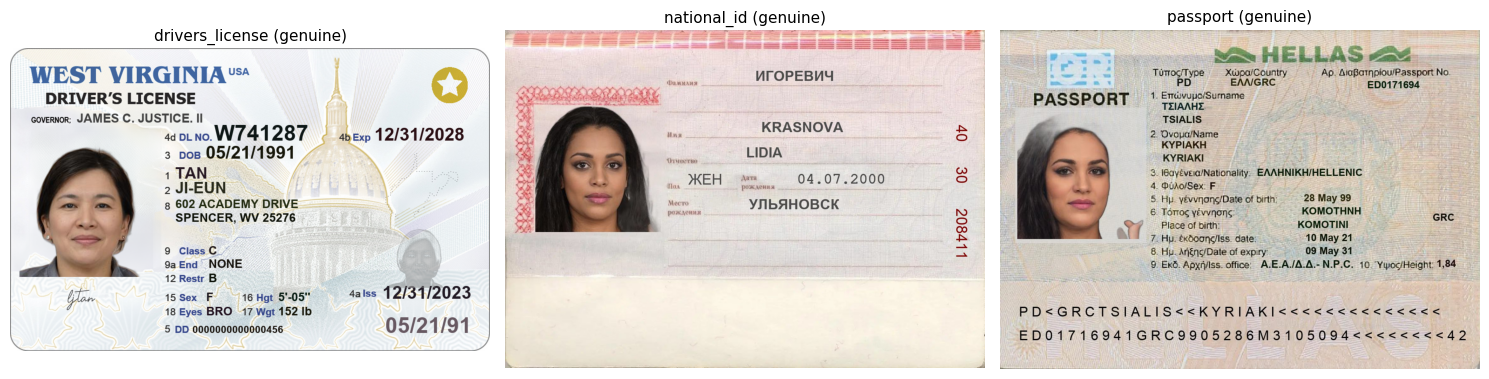

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, labels):
    matching = [f for f in all_files if f.startswith(label)]
    img = Image.open(os.path.join(raw_dir, matching[0]))
    ax.imshow(img)
    ax.set_title(f"{label} (genuine)", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **4. Synthetic Fake Generation**
### 4.1 Apply Gaussian blur to create fake subset

In [24]:
# Fake generation
# For each doc type: first 100 images stay genuine, next 100 become fakes.
# Fakes get one tampering method. Both genuine and fake images can also get
# "capture" effects (noise, lighting, jpeg) at the same rate, so the model
# can't just learn that noisy images are fake.

import random
random.seed(42)
np.random.seed(42)


# --- noise functions ---

def add_noise(img, sigma):
    # gaussian noise, basically camera grain
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def poisson_noise(img, scale=30):
    # noise that's stronger in brighter areas (low light photos)
    # smaller scale = more noise
    vals = np.clip(img.astype(np.float32) / 255.0 * scale, 0, None)
    return np.clip(np.random.poisson(vals) / scale * 255.0, 0, 255).astype(np.uint8)

def salt_pepper(img, amount=0.01):
    # random black and white pixels
    out = img.copy()
    mask = np.random.random(img.shape[:2])
    out[mask < amount / 2] = 0
    out[mask > 1 - amount / 2] = 255
    return out

def jpeg_compress(img, quality):
    # re-save as jpeg, lower quality = more compression artifacts
    ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR)

def edit_traces(patch):
    # pasted areas usually don't match the rest of the card exactly:
    # different jpeg quality and slightly different brightness
    patch = jpeg_compress(patch, random.randint(30, 70))
    return cv2.convertScaleAbs(patch, alpha=random.uniform(0.92, 1.08), beta=random.randint(-10, 10))


# --- capture effects (used on both genuine and fake) ---

CAPTURE_RATE = 0.6  # same rate for both classes on purpose

def capture(img):
    # tries to look like someone took a photo of their ID and uploaded it
    if random.random() < 0.5:
        img = cv2.GaussianBlur(img, (3, 3), 0)  # slight blur, weaker than the fake blurs (5+)

    # small brightness/contrast change
    img = cv2.convertScaleAbs(img, alpha=random.uniform(0.85, 1.15), beta=random.randint(-20, 20))

    # one random noise type
    method = random.choice(["gaussian", "poisson", "saltpepper", "jpeg"])
    if method == "gaussian":
        img = add_noise(img, random.uniform(2, 15))
    elif method == "poisson":
        img = poisson_noise(img, scale=random.uniform(20, 60))
    elif method == "saltpepper":
        img = salt_pepper(img, random.uniform(0.001, 0.01))
    else:
        img = jpeg_compress(img, random.randint(50, 95))
    return img


# --- tampering methods (fakes only) ---
# each one returns (image, tag). tag goes in the filename so we can check
# later which types the models miss. no underscores in tags since we split on "_"

def rand_region(h, w, lo, hi):
    # random box inside the image, size is lo-hi fraction of height/width
    rh, rw = int(h * random.uniform(lo, hi)), int(w * random.uniform(lo, hi))
    return rh, rw, random.randint(0, h - rh), random.randint(0, w - rw)

def blur_full(img):
    # whole image blurred. kept low weight since this looks more like a bad photo than a fake
    k = random.choice([5, 7, 11, 15])
    return cv2.GaussianBlur(img, (k, k), 0), f"full{k}"

def blur_partial(img):
    # blur just one area
    k = random.choice([5, 7, 11, 15, 21])
    h, w = img.shape[:2]
    rh, rw, y, x = rand_region(h, w, 0.15, 0.35)
    out = img.copy()
    out[y:y+rh, x:x+rw] = cv2.GaussianBlur(img[y:y+rh, x:x+rw], (k, k), 0)
    return out, f"partial{k}"

def copy_move(img):
    # copy part of the card and paste it somewhere else on the same card
    h, w = img.shape[:2]
    rh, rw, y1, x1 = rand_region(h, w, 0.10, 0.25)
    y2, x2 = random.randint(0, h - rh), random.randint(0, w - rw)
    out = img.copy()
    out[y2:y2+rh, x2:x2+rw] = edit_traces(img[y1:y1+rh, x1:x1+rw])
    return out, "copymove"

def splice(img, donor):
    # paste a piece from a different card of the same type
    # (like swapping in someone else's photo)
    donor = cv2.resize(donor, (img.shape[1], img.shape[0]))  # same size so coords match
    h, w = img.shape[:2]
    rh, rw, y, x = rand_region(h, w, 0.15, 0.30)
    out = img.copy()
    out[y:y+rh, x:x+rw] = edit_traces(donor[y:y+rh, x:x+rw])
    return out, "splice"

def text_tamper(img):
    # cover a small strip and write a fake date over it
    h, w = img.shape[:2]
    scale = w / 1200  # images are ~1000-1500px wide, so scale text to fit

    y = random.randint(int(h * 0.3), int(h * 0.85))
    x = random.randint(int(w * 0.3), int(w * 0.6))
    color = tuple(int(c) for c in img[y, x])  # grab background color so the box blends in

    out = img.copy()
    y0, y1 = max(0, y - int(30 * scale)), min(h, y + int(8 * scale))
    x0, x1 = x, min(w, x + int(220 * scale))
    cv2.rectangle(out, (x0, y0), (x1, y1), color, -1)
    cv2.putText(out, f"{random.randint(1, 28):02d}.{random.randint(1, 12):02d}.{random.randint(1950, 2005)}",
                (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8 * scale, (30, 30, 30), max(1, int(2 * scale)))

    # edited strip saved differently from the rest of the card
    out[y0:y1, x0:x1] = edit_traces(out[y0:y1, x0:x1])
    return out, "text"


# how often each tampering type gets picked
TAMPER_WEIGHTS = {"blur_full": 0.10, "blur_partial": 0.25, "copy_move": 0.20,
                  "splice": 0.25, "text": 0.20}

def make_fake(img, donor):
    # pick one tampering method based on the weights above
    choice = random.choices(list(TAMPER_WEIGHTS), weights=TAMPER_WEIGHTS.values())[0]
    if choice == "blur_full":      return blur_full(img)
    if choice == "blur_partial":   return blur_partial(img)
    if choice == "copy_move":      return copy_move(img)
    if choice == "splice":         return splice(img, donor)
    return text_tamper(img)


# --- build the dataset ---

output_dir = "/content/final_sample"
shutil.rmtree(output_dir, ignore_errors=True)  # clear old run
os.makedirs(output_dir, exist_ok=True)

for label in labels:
    matching = sorted(f for f in all_files if f.startswith(label))
    genuine_files = matching[:100]
    fake_files = matching[100:200]

    # genuine: no tampering, just maybe capture effects
    for f in genuine_files:
        img = cv2.imread(os.path.join(raw_dir, f))
        if random.random() < CAPTURE_RATE:
            img = capture(img)
        cv2.imwrite(os.path.join(output_dir, f"{label}_genuine_{f}"), img)

    # fake: tamper first, then maybe capture effects (same rate as genuine)
    for f in fake_files:
        img = cv2.imread(os.path.join(raw_dir, f))

        # donor for splice comes from the fake pool so genuine images don't leak into fakes
        donor_name = random.choice([d for d in fake_files if d != f])
        donor = cv2.imread(os.path.join(raw_dir, donor_name))

        fake, tag = make_fake(img, donor)
        if random.random() < CAPTURE_RATE:
            fake = capture(fake)

        cv2.imwrite(os.path.join(output_dir, f"{label}_fake_{tag}_{f}"), fake)

# check: should be 600 total, plus a count of each tampering type
print(f"Total in final_sample: {len(os.listdir(output_dir))}")
print(Counter(f.split("_fake_")[1].split("_")[0].rstrip("0123456789")  # "partial11" -> "partial"
              for f in os.listdir(output_dir) if "_fake_" in f))

Total in final_sample: 600
Counter({'splice': 80, 'partial': 74, 'copymove': 61, 'text': 56, 'full': 29})


### 4.2 Visualize genuine vs. fake side-by-side

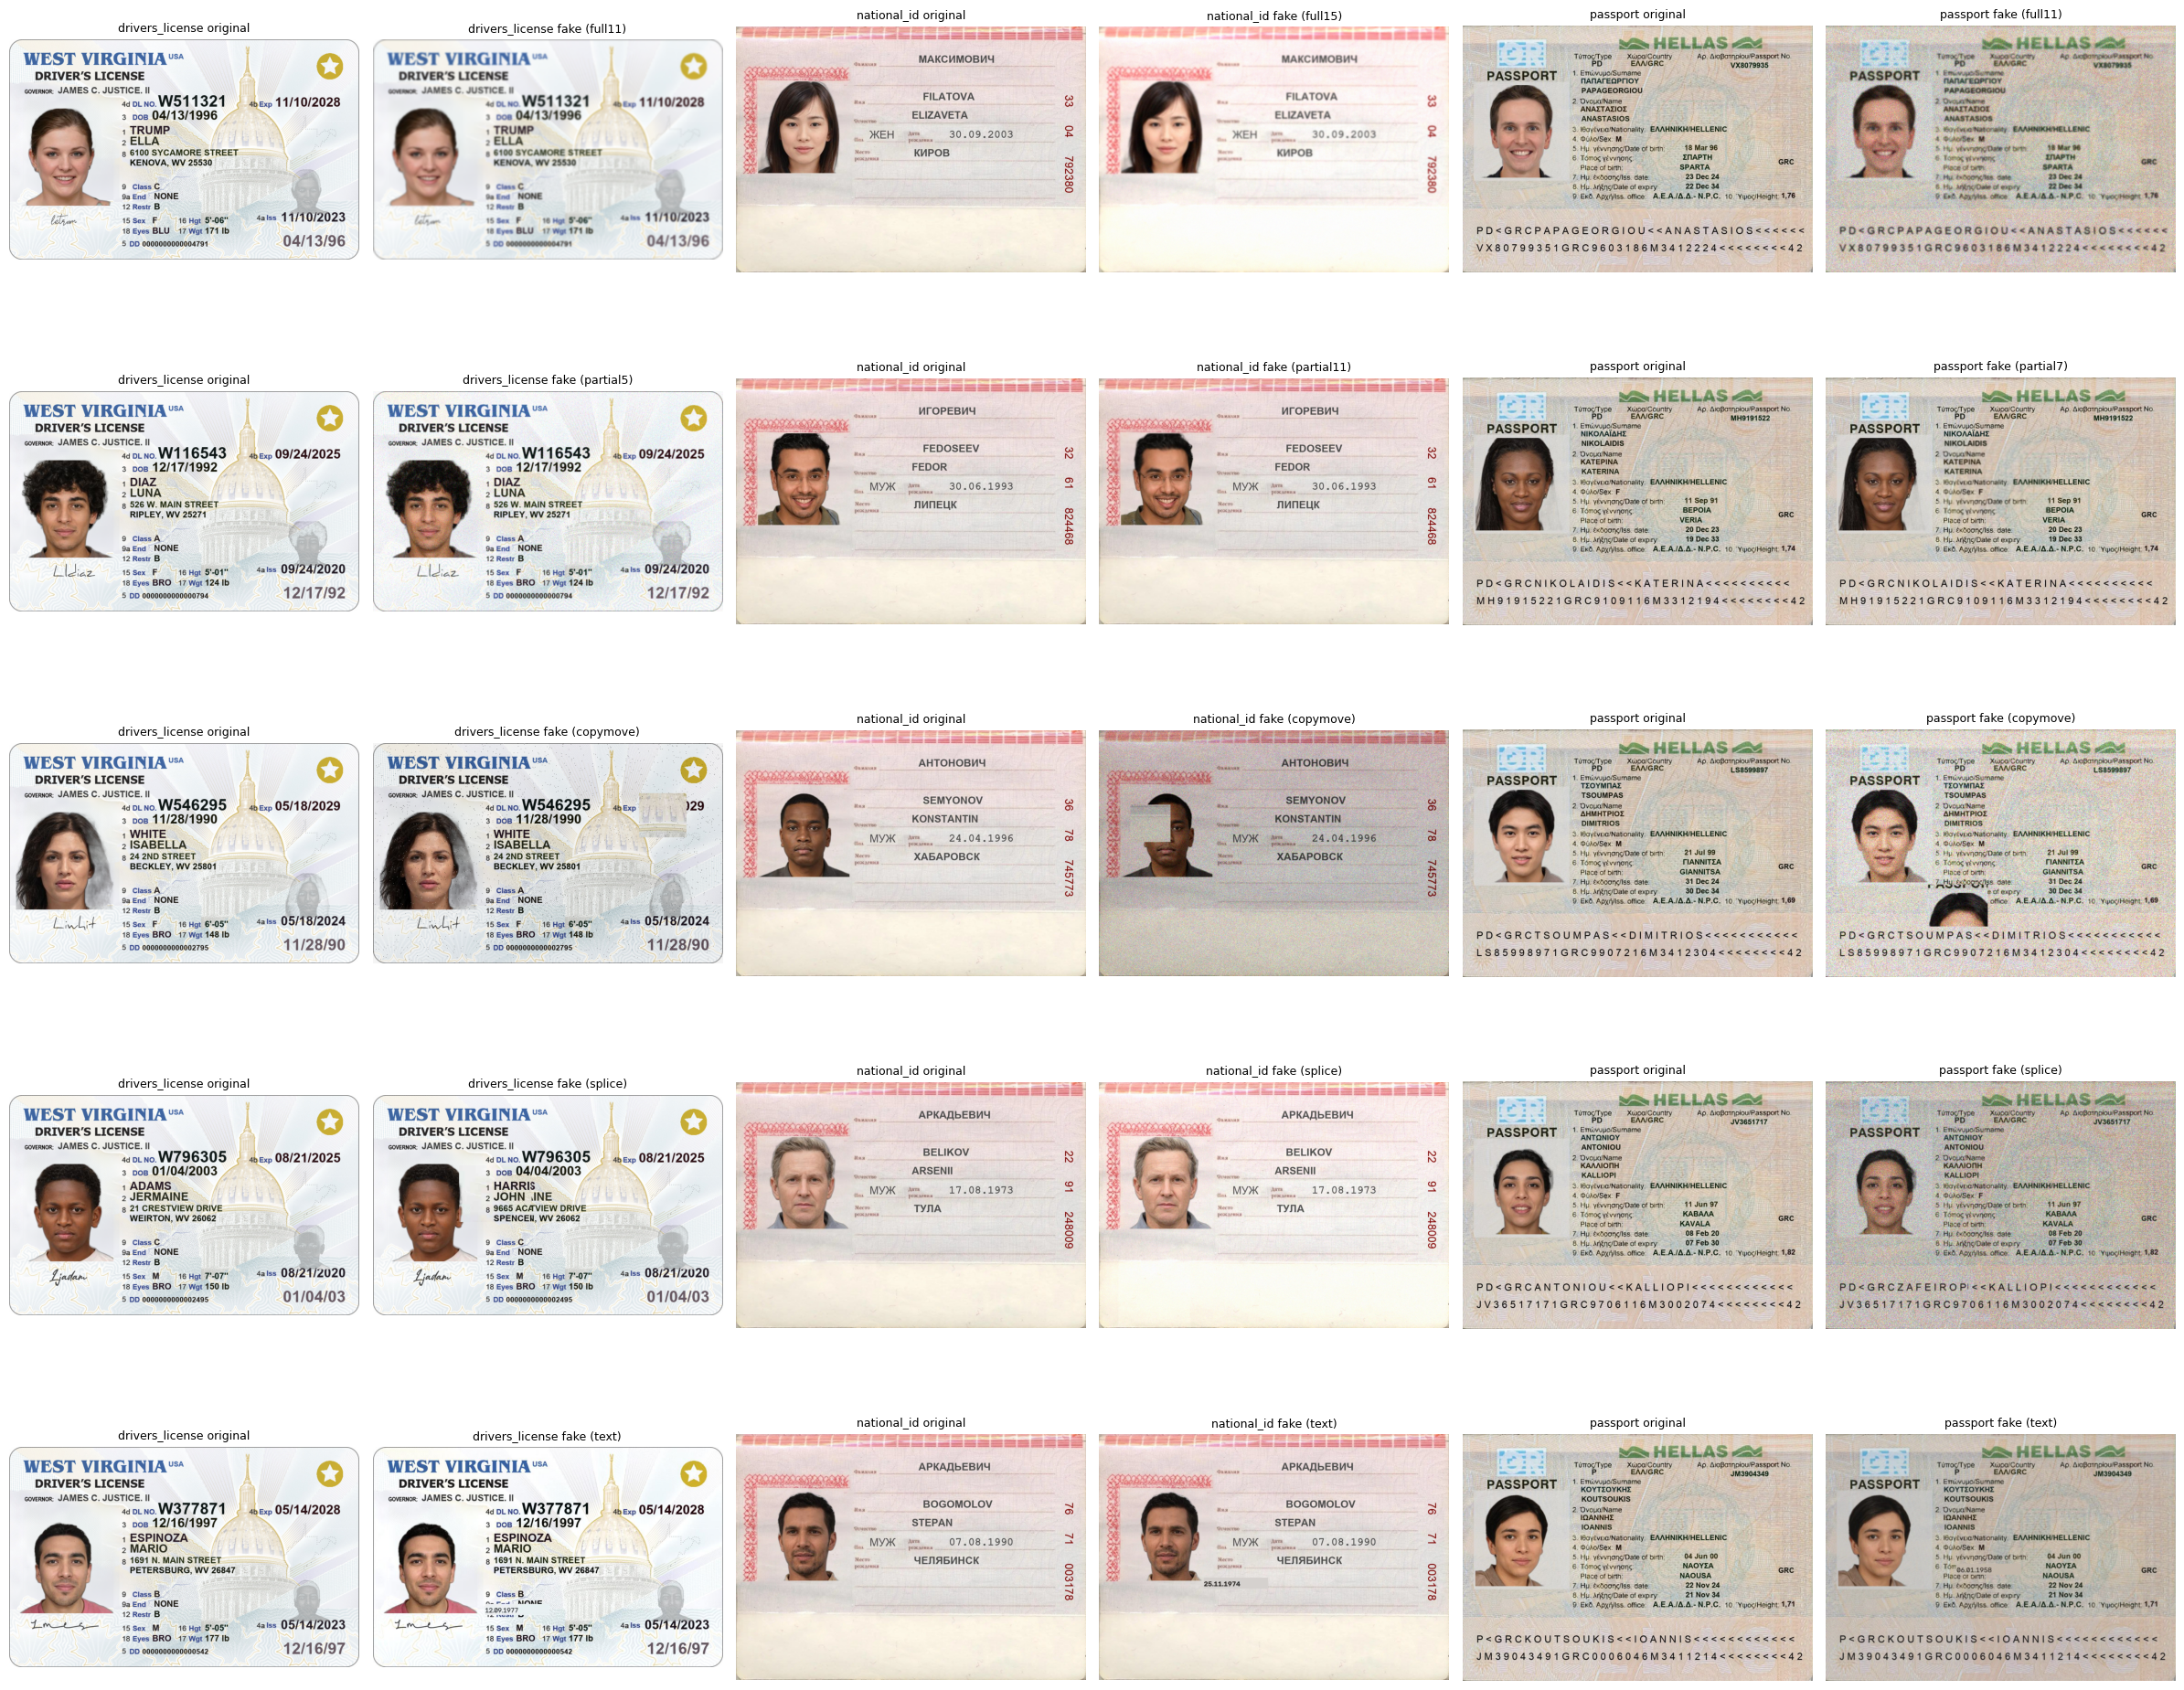

In [27]:
# show one example of each tampering type for each doc type, original next to the fake
fake_files = sorted(f for f in os.listdir(output_dir) if "_fake_" in f)
kinds = ["full", "partial", "copymove", "splice", "text"]

# rows = tampering type, columns = (original, fake) for each doc type
fig, axes = plt.subplots(len(kinds), len(labels) * 2, figsize=(24, 4 * len(kinds)))

for r, kind in enumerate(kinds):
    for c, label in enumerate(labels):
        ax_orig, ax_fake = axes[r, c * 2], axes[r, c * 2 + 1]
        ax_orig.axis("off")
        ax_fake.axis("off")

        options = [x for x in fake_files if x.startswith(f"{label}_fake_{kind}")]
        if not options:  # random weights might skip a type for some doc type
            ax_fake.set_title(f"{label}: no {kind} fakes", fontsize=9)
            continue

        f = random.choice(options)
        tag, original_name = f[len(f"{label}_fake_"):].split("_", 1)

        original = cv2.imread(os.path.join(raw_dir, original_name))
        fake = cv2.imread(os.path.join(output_dir, f))

        ax_orig.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
        ax_orig.set_title(f"{label} original", fontsize=9)
        ax_fake.imshow(cv2.cvtColor(fake, cv2.COLOR_BGR2RGB))
        ax_fake.set_title(f"{label} fake ({tag})", fontsize=9)

plt.tight_layout()
plt.show()

### 4.3 Confirm final_sample: 600 total, labeled genuine/fake

In [28]:
final_files = os.listdir(output_dir)
final_counts = Counter()

for f in final_files:
    for label in labels:
        for kind in ["genuine", "fake"]:
            if f.startswith(f"{label}_{kind}"):
                final_counts[f"{label}_{kind}"] += 1

for k, v in final_counts.items():
    print(f"{k}: {v}")
print(f"Total: {sum(final_counts.values())}")

national_id_genuine: 100
passport_genuine: 100
drivers_license_genuine: 100
national_id_fake: 100
passport_fake: 100
drivers_license_fake: 100
Total: 600


## 5. Feature extraction (HOG + LBP)

In [29]:
from skimage.feature import hog, local_binary_pattern

IMG_SIZE = (512, 320)   # used for LBP, color, and HOG
GRID = 8                # 8x8 grid for local features
USE_HOG = False         # hog mostly describes card content, not edits

def grid(arr, n=GRID):
    # split image into an n x n grid of cells
    h, w = arr.shape[:2]
    return [arr[i*h//n:(i+1)*h//n, j*w//n:(j+1)*w//n] for i in range(n) for j in range(n)]

def anomaly_stats(vals):
    # how much the most unusual cells stand out from the rest of the card.
    # doesn't depend on where the edit is
    v = np.asarray(vals, dtype=np.float32)
    med = np.median(v)
    mad = np.median(np.abs(v - med)) + 1e-6
    z = np.abs(v - med) / mad
    return [v.max(), v.min(), v.std(), v.max() - v.min(), z.max(), np.sort(z)[-3:].mean()]

def copy_move_score(gray):
    # find keypoints that look almost the same but sit in different spots on the card.
    # a copied region creates a lot of these
    f = 1000 / gray.shape[1]
    g = cv2.resize(gray, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    orb = cv2.ORB_create(nfeatures=1500)
    kps, des = orb.detectAndCompute(g, None)
    if des is None or len(kps) < 3:
        return [0, 0]

    matches = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des, des, k=3)
    count = 0
    for m in matches:
        others = [x for x in m if x.trainIdx != x.queryIdx]  # skip matching a point to itself
        if len(others) < 2:
            continue
        a, b = others[0], others[1]
        if a.distance < 40 and a.distance < 0.7 * b.distance:
            p1, p2 = kps[a.queryIdx].pt, kps[a.trainIdx].pt
            if np.hypot(p1[0] - p2[0], p1[1] - p2[1]) > 40:  # ignore neighbors
                count += 1
    return [count, count / len(kps)]

def extract_features(path):
    img = cv2.imread(path)
    gray_full = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # --- full resolution features (resizing would smooth these out) ---

    # noise level per cell: pasted areas often have different noise
    residual = gray_full.astype(np.float32) - cv2.medianBlur(gray_full, 3).astype(np.float32)
    noise_cells = [c.std() for c in grid(residual)]

    # ELA per cell: how much each area changes when re-saved as jpeg
    ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
    ela = cv2.absdiff(img, cv2.imdecode(enc, cv2.IMREAD_COLOR)).astype(np.float32).mean(axis=2)
    ela_cells = [c.mean() for c in grid(ela)]

    # sharpness per cell: blurred areas are softer, pasted text is sharper
    lap = cv2.Laplacian(gray_full, cv2.CV_32F)
    sharp_cells = [c.var() for c in grid(lap)]

    # --- resized features ---
    small = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)

    # LBP texture: 4x4 histograms, plus how different each 8x8 cell is from the card's average texture
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_vec = np.concatenate([np.histogram(c, bins=10, range=(0, 10), density=True)[0] for c in grid(lbp, 4)])
    hists = np.array([np.histogram(c, bins=10, range=(0, 10), density=True)[0] for c in grid(lbp)])
    mean_hist = hists.mean(axis=0)
    lbp_dist = ((hists - mean_hist) ** 2 / (hists + mean_hist + 1e-6)).sum(axis=1)

    # color: mean HSV per 4x4 cell, plus how far each cell is from the card's average color
    hsv = cv2.cvtColor(small, cv2.COLOR_BGR2HSV).astype(np.float32)
    color_cells = np.array([c.reshape(-1, 3).mean(axis=0) for c in grid(hsv, 4)])
    color_dev = np.linalg.norm(color_cells - color_cells.mean(axis=0), axis=1)

    parts = {
        "lbp": lbp_vec,
        "noise": noise_cells,
        "ela": ela_cells,
        "sharp": sharp_cells,
        "color": color_cells.ravel(),
        "anomaly": (anomaly_stats(noise_cells) + anomaly_stats(ela_cells) + anomaly_stats(sharp_cells)
                    + anomaly_stats(lbp_dist) + anomaly_stats(color_dev)),
        "copymove": copy_move_score(gray_full),
    }
    if USE_HOG:
        parts["hog"] = hog(gray, orientations=9, pixels_per_cell=(32, 32), cells_per_block=(2, 2))

    return np.concatenate([np.asarray(v, dtype=np.float32) for v in parts.values()]), parts

files = sorted(os.listdir(output_dir))
feats = [extract_features(os.path.join(output_dir, f)) for f in files]
X = np.array([vec for vec, _ in feats])
y = np.array([1 if "_fake_" in f else 0 for f in files])          # 1 = fake, 0 = genuine
doc_type = np.array([next(l for l in labels if f.startswith(l)) for f in files])

# which columns belong to which feature group (for feature importance later)
feature_groups, start = {}, 0
for name, v in feats[0][1].items():
    feature_groups[name] = slice(start, start + len(v))
    start += len(v)

print("Feature matrix:", X.shape)
for name, s in feature_groups.items():
    print(f"  {name}: {s.stop - s.start} features")
print("Fake:", y.sum(), "| Genuine:", len(y) - y.sum())

Feature matrix: (600, 432)
  lbp: 160 features
  noise: 64 features
  ela: 64 features
  sharp: 64 features
  color: 48 features
  anomaly: 30 features
  copymove: 2 features
Fake: 300 | Genuine: 300


## 6. Train / Test Split (80-20)

In [30]:
from sklearn.model_selection import train_test_split

def tamper_type(f):
    # "genuine" for real images, otherwise the tampering tag without the blur size
    if "_fake_" not in f:
        return "genuine"
    return f.split("_fake_")[1].split("_")[0].rstrip("0123456789")

# stratify by doc type + tampering type, so train and test get the same mix
strata = [f"{d}_{tamper_type(f)}" for d, f in zip(doc_type, files)]

X_train, X_test, y_train, y_test, f_train, f_test = train_test_split(
    X, y, np.array(files), test_size=0.2, stratify=strata, random_state=42
)
print("Train:", len(y_train), "| Test:", len(y_test))
print("Test mix:", Counter(tamper_type(f) for f in f_test))

Train: 480 | Test: 120
Test mix: Counter({'genuine': 60, 'splice': 16, 'partial': 15, 'copymove': 12, 'text': 11, 'full': 6})


## 7. Model Training

### 7.1 Initial models: Logistic Regression, SVM, Random Forest

In [31]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

K_LINEAR = 200  # keep the 200 features most related to genuine vs fake

models = {
    # scale, pick the best features, then the model
    # lower C = simpler model
    "Logistic Regression": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_LINEAR),
                                         LogisticRegression(C=0.1, max_iter=2000)),
    "SVM (Linear)":        make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_LINEAR),
                                         SVC(kernel="linear", C=0.1, probability=True, random_state=42)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_LINEAR),
                                         SVC(kernel="rbf", C=1.0, probability=True, random_state=42)),

    # no feature selection here so we can still check feature importance later
    # min_samples_leaf stops it from memorizing single images
    "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                  max_features="sqrt", n_jobs=-1, random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name}: train acc {m.score(X_train, y_train):.3f}")  # check if still at 1.000

Logistic Regression: train acc 0.721
SVM (Linear): train acc 0.735
SVM (RBF): train acc 0.648
Random Forest: train acc 1.000


### 7.2 Additional models: Decision Tree, Extra Trees, AdaBoost, Gradient Boosting

In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, AdaBoostClassifier, HistGradientBoostingClassifier

# tree-based models, so no scaling or PCA needed
# each one has a few limits added since they were all hitting 100% train accuracy before
new_models = {
    # single tree, capped at depth 8 so it can't keep splitting until every image is memorized
    "Decision Tree":     DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=42),

    # like random forest but with more random splits, same limits as RF
    "Extra Trees":       ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3,
                                              max_features="sqrt", n_jobs=-1, random_state=42),

    # lower learning rate so each new model only fixes a little of the previous mistakes
    "AdaBoost":          AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42),

    # shallow trees + L2 penalty, and early stopping quits once the validation score stops improving
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                                        l2_regularization=1.0, early_stopping=True,
                                                        random_state=42),
}

# train each model and print train accuracy to see if it's still overfitting
for name, m in new_models.items():
    m.fit(X_train, y_train)
    print(f"{name}: train acc {m.score(X_train, y_train):.3f}")

Decision Tree: train acc 0.800
Extra Trees: train acc 0.998
AdaBoost: train acc 0.790
Gradient Boosting: train acc 0.908


** 7.3 More models: MLP (DNN), KNN, Naive Bayes, LDA, XGBoost, LightGBM**

In [33]:
# 7.3 More models
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

K_BEST = 300  # keep the 300 features most related to genuine vs fake

extra_models = {
    # small neural net, more patience before early stopping
    "MLP (DNN)":   make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3,
                                               early_stopping=True, validation_fraction=0.2,
                                               n_iter_no_change=30, max_iter=1000, random_state=42)),

    # these need fewer features, so pick the most useful ones first
    "KNN":         make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 GaussianNB()),
    "LDA":         make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 LinearDiscriminantAnalysis()),

    # boosting, no feature reduction needed
    "XGBoost":     XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.3, eval_metric="logloss",
                                 random_state=42),
    "LightGBM":    LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.3,
                                  verbose=-1, random_state=42),
}

for name, m in extra_models.items():
    m.fit(X_train, y_train)
    print(f"{name}: train acc {m.score(X_train, y_train):.3f}")

MLP (DNN): train acc 0.885
KNN: train acc 0.677
Naive Bayes: train acc 0.573
LDA: train acc 0.950
XGBoost: train acc 1.000
LightGBM: train acc 1.000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### 7.3 Join Models

In [34]:
all_models = {**models, **new_models, **extra_models}   # teammates add their dicts here, e.g. **teammate_models
print(len(all_models), "models:", list(all_models))

14 models: ['Logistic Regression', 'SVM (Linear)', 'SVM (RBF)', 'Random Forest', 'Decision Tree', 'Extra Trees', 'AdaBoost', 'Gradient Boosting', 'MLP (DNN)', 'KNN', 'Naive Bayes', 'LDA', 'XGBoost', 'LightGBM']


In [38]:
# soft voting: average the fake-probability of the best models
from sklearn.ensemble import VotingClassifier

top = ["Random Forest", "LightGBM", "MLP (DNN)", "XGBoost", "AdaBoost"]
ensemble = VotingClassifier([(n, all_models[n]) for n in top], voting="soft", n_jobs=-1)
ensemble.fit(X_train, y_train)
all_models["Ensemble (top 5)"] = ensemble
print(f"Ensemble: train acc {ensemble.score(X_train, y_train):.3f}, test acc {ensemble.score(X_test, y_test):.3f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Ensemble: train acc 1.000, test acc 0.750


## 8. Model Evaluation

### 8.1 Metrics comparison (all models)

In [39]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

rows = []
for name, m in all_models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Train acc": m.score(X_train, y_train),
    })

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results["Gap (train − test)"] = results["Train acc"] - results["Accuracy"]
results.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train acc,Gap (train − test)
0,Ensemble (top 5),0.750,0.826,0.633,0.717,0.802,1.000,0.250
1,LightGBM,0.717,0.771,0.617,0.685,0.785,1.000,0.283
2,Random Forest,0.717,0.783,0.600,0.679,0.781,1.000,0.283
3,MLP (DNN),0.708,0.778,0.583,0.667,0.756,0.885,0.177
4,XGBoost,0.700,0.773,0.567,0.654,0.790,1.000,0.300
5,Extra Trees,0.692,0.795,0.517,0.626,0.771,0.998,0.306
6,AdaBoost,0.692,0.795,0.517,0.626,0.755,0.790,0.098
7,Gradient Boosting,0.683,0.762,0.533,0.627,0.758,0.908,0.225
8,Logistic Regression,0.642,0.698,0.500,0.583,0.676,0.721,0.079
9,SVM (Linear),0.633,0.750,0.400,0.522,0.666,0.735,0.102


### 8.2 Confusion matrices

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


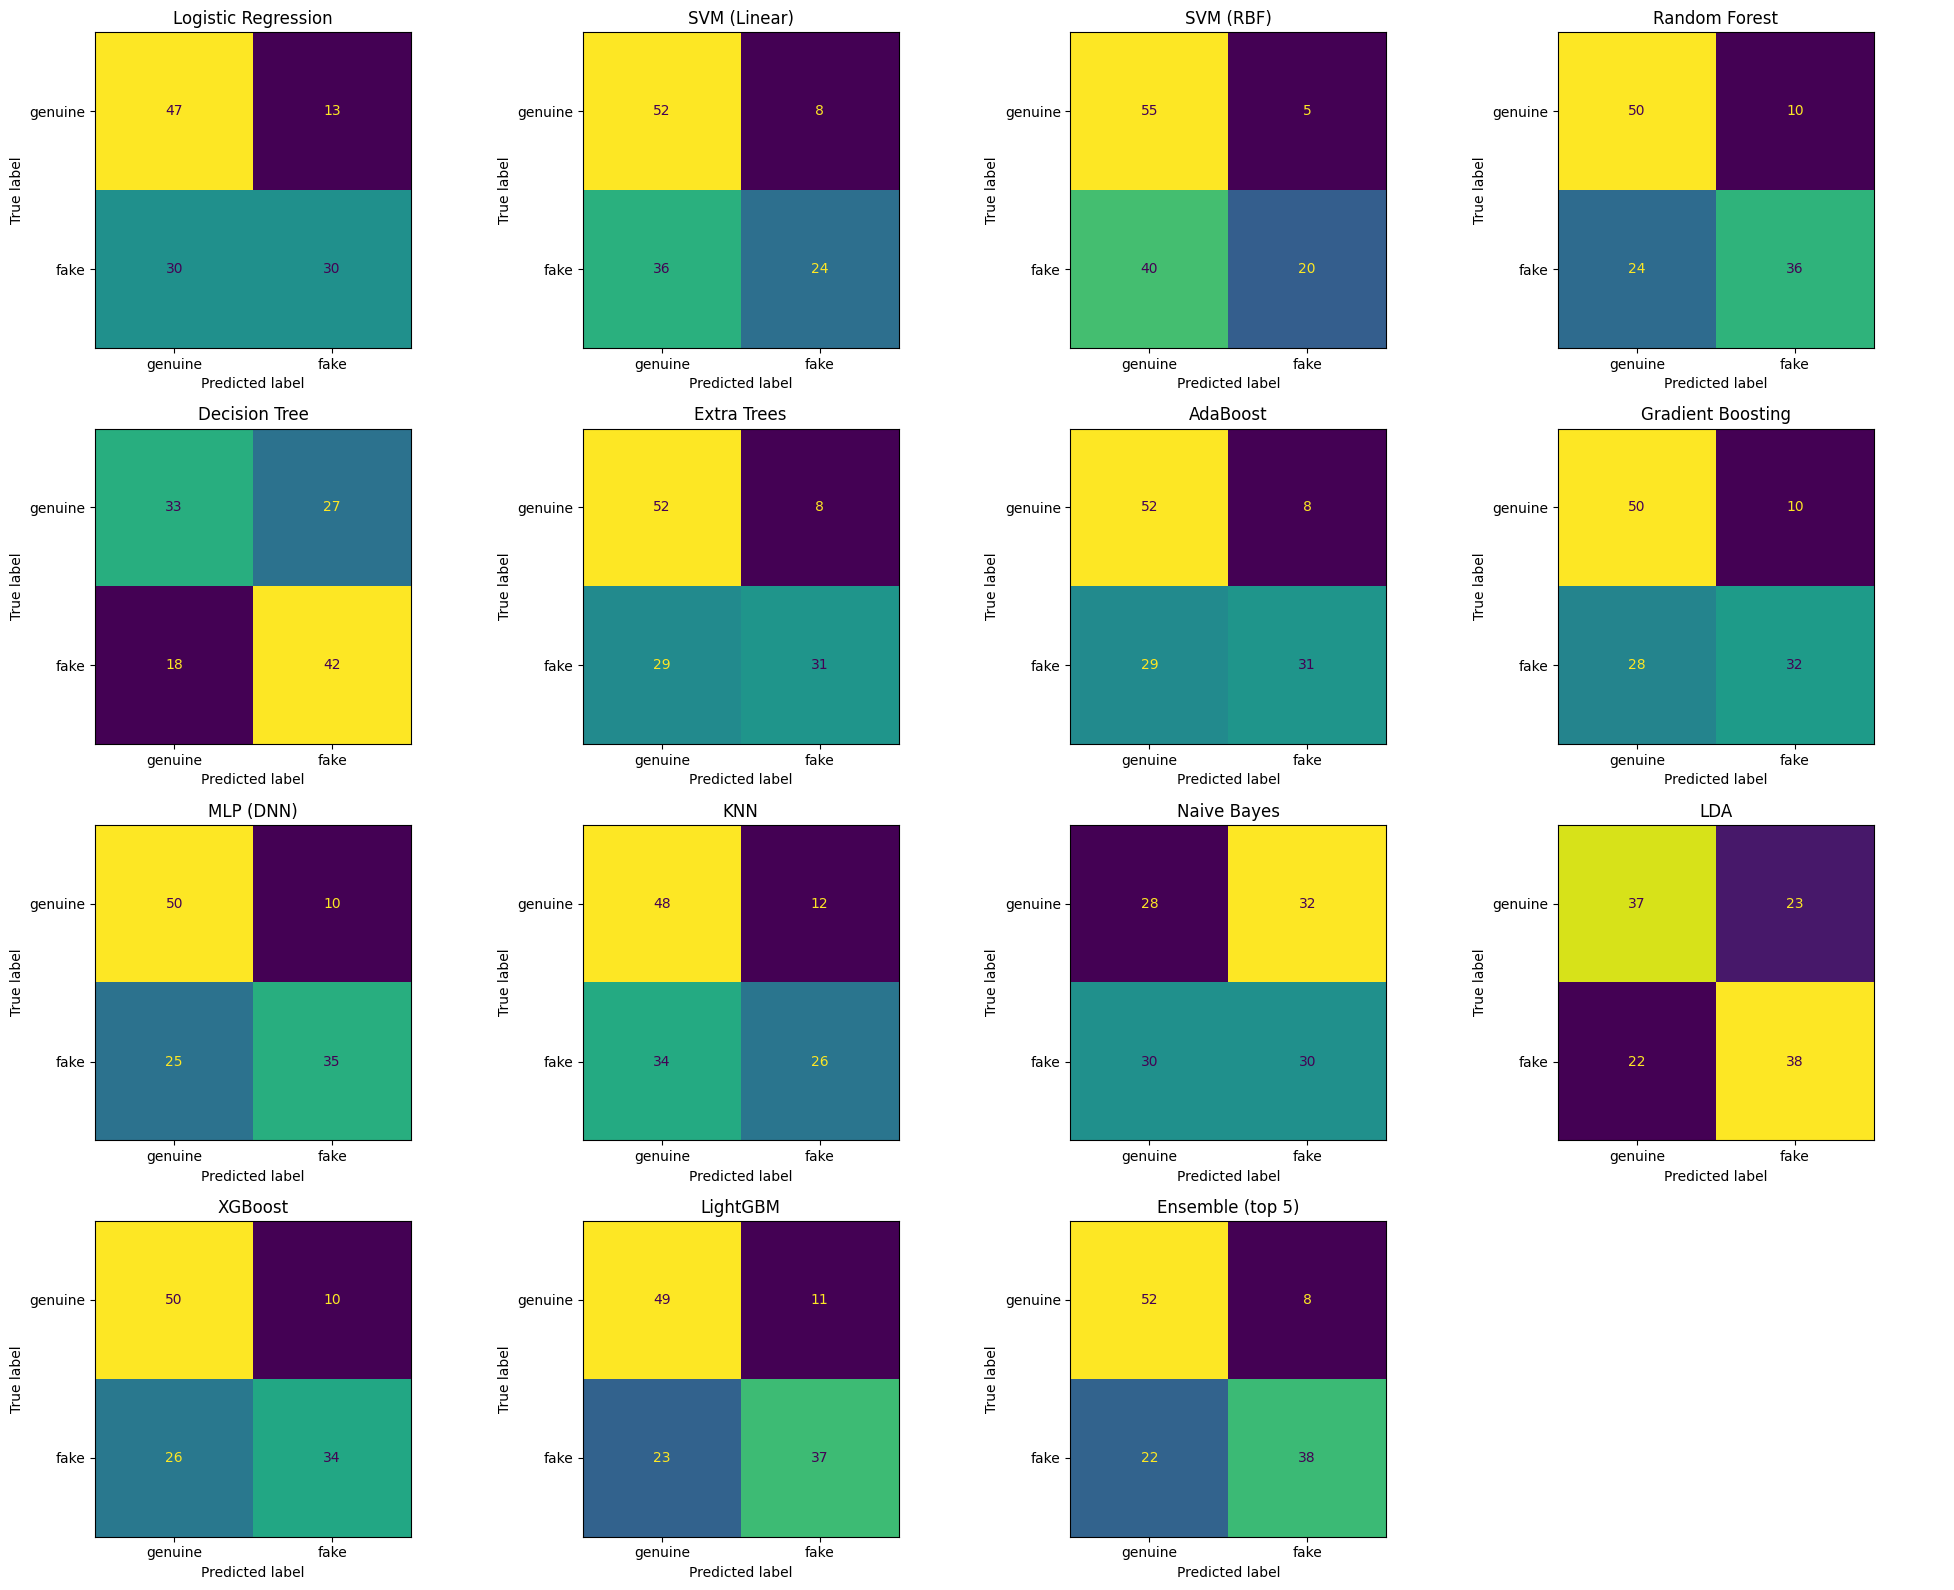

In [40]:
import math
from sklearn.metrics import ConfusionMatrixDisplay

n_cols = 4
n_rows = math.ceil(len(all_models) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
for ax, (name, m) in zip(axes.flat, all_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test,
                                          display_labels=["genuine", "fake"],
                                          ax=ax, colorbar=False)
    ax.set_title(name)
for ax in axes.flat[len(all_models):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 8.3 Fakes caught by type (full vs. partial blur)

In [41]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, m in all_models.items():
    # n_jobs=-1 runs the 5 folds in parallel, much faster
    scores = cross_val_score(m, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_rows.append({"Model": name, "CV accuracy": scores.mean(), "Std": scores.std()})
    print(f"{name:20s} {scores.mean():.3f} ± {scores.std():.3f}")

pd.DataFrame(cv_rows).sort_values("CV accuracy", ascending=False).reset_index(drop=True).round(3)

Logistic Regression  0.613 ± 0.029
SVM (Linear)         0.620 ± 0.027
SVM (RBF)            0.572 ± 0.029
Random Forest        0.663 ± 0.041
Decision Tree        0.630 ± 0.025
Extra Trees          0.638 ± 0.012
AdaBoost             0.658 ± 0.018
Gradient Boosting    0.687 ± 0.021
MLP (DNN)            0.648 ± 0.041
KNN                  0.543 ± 0.027
Naive Bayes          0.557 ± 0.053
LDA                  0.588 ± 0.043
XGBoost              0.680 ± 0.027
LightGBM             0.695 ± 0.020
Ensemble (top 5)     0.685 ± 0.021


,Model,CV accuracy,Std
0,LightGBM,0.695,0.020
1,Gradient Boosting,0.687,0.021
2,Ensemble (top 5),0.685,0.021
3,XGBoost,0.680,0.027
4,Random Forest,0.663,0.041
5,AdaBoost,0.658,0.018
6,MLP (DNN),0.648,0.041
7,Extra Trees,0.638,0.012
8,Decision Tree,0.630,0.025
9,SVM (Linear),0.620,0.027


### 8.4 Confusion counts (TP / FN / FP / TN)

In [42]:
from sklearn.metrics import confusion_matrix

for name, m in all_models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    print(f"{name:20s} TP {tp} | FN {fn} | FP {fp} | TN {tn}")

Logistic Regression  TP 30 | FN 30 | FP 13 | TN 47
SVM (Linear)         TP 24 | FN 36 | FP 8 | TN 52
SVM (RBF)            TP 20 | FN 40 | FP 5 | TN 55
Random Forest        TP 36 | FN 24 | FP 10 | TN 50
Decision Tree        TP 42 | FN 18 | FP 27 | TN 33
Extra Trees          TP 31 | FN 29 | FP 8 | TN 52
AdaBoost             TP 31 | FN 29 | FP 8 | TN 52
Gradient Boosting    TP 32 | FN 28 | FP 10 | TN 50
MLP (DNN)            TP 35 | FN 25 | FP 10 | TN 50
KNN                  TP 26 | FN 34 | FP 12 | TN 48
Naive Bayes          TP 30 | FN 30 | FP 32 | TN 28
LDA                  TP 38 | FN 22 | FP 23 | TN 37
XGBoost              TP 34 | FN 26 | FP 10 | TN 50
LightGBM             TP 37 | FN 23 | FP 11 | TN 49


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Ensemble (top 5)     TP 38 | FN 22 | FP 8 | TN 52


### 8.5 Cross-validation

In [43]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, m in all_models.items():
    # n_jobs=-1 runs the 5 folds in parallel, much faster
    scores = cross_val_score(m, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_rows.append({"Model": name, "CV accuracy": scores.mean(), "Std": scores.std()})
    print(f"{name:20s} {scores.mean():.3f} ± {scores.std():.3f}")

pd.DataFrame(cv_rows).sort_values("CV accuracy", ascending=False).reset_index(drop=True).round(3)

Logistic Regression  0.613 ± 0.029
SVM (Linear)         0.620 ± 0.027
SVM (RBF)            0.572 ± 0.029
Random Forest        0.663 ± 0.041
Decision Tree        0.630 ± 0.025
Extra Trees          0.638 ± 0.012
AdaBoost             0.658 ± 0.018
Gradient Boosting    0.687 ± 0.021
MLP (DNN)            0.648 ± 0.041
KNN                  0.543 ± 0.027
Naive Bayes          0.557 ± 0.053
LDA                  0.588 ± 0.043
XGBoost              0.680 ± 0.027
LightGBM             0.695 ± 0.020
Ensemble (top 5)     0.685 ± 0.021


,Model,CV accuracy,Std
0,LightGBM,0.695,0.020
1,Gradient Boosting,0.687,0.021
2,Ensemble (top 5),0.685,0.021
3,XGBoost,0.680,0.027
4,Random Forest,0.663,0.041
5,AdaBoost,0.658,0.018
6,MLP (DNN),0.648,0.041
7,Extra Trees,0.638,0.012
8,Decision Tree,0.630,0.025
9,SVM (Linear),0.620,0.027


## 9. Demo: Classify an Uploaded Image

In [ ]:
def predict_image(path):
    feats = extract_features(path).reshape(1, -1)
    results = []
    for name, m in all_models.items():
        p = m.predict_proba(feats)[0, 1]          # probability of fake
        verdict = "FAKE" if p >= 0.5 else "GENUINE"
        results.append(f"{name}: {verdict} ({p:.0%} fake)")
    return results

In [ ]:
from google.colab import files as colab_files

uploaded = colab_files.upload()

for name in uploaded:
    path = f"/content/{name}"
    if cv2.imread(path) is None:
        print(f"{name}: couldn't read it. Use a .jpg or .png file.")
        continue

    feats = extract_features(path).reshape(1, -1)
    probs = {}
    print(name)
    for model_name, m in all_models.items():
        p_fake = m.predict_proba(feats)[0, 1]
        probs[model_name] = p_fake
        verdict = "FAKE" if p_fake >= 0.5 else "GENUINE"
        print(f"  {model_name:20s} {verdict:8s} genuine {1 - p_fake:.0%} | fake {p_fake:.0%}")

    avg = np.mean(list(probs.values()))
    final = "FAKE" if avg >= 0.5 else "GENUINE"
    print(f"  FINAL (average)      {final:8s} genuine {1 - avg:.0%} | fake {avg:.0%}")

    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    plt.title(f"{final}: genuine {1 - avg:.0%} | fake {avg:.0%}")
    plt.axis("off")
    plt.show()